# 03 – Análise exploratória e hipóteses para a modelagem

Antes de treinar qualquer modelo, é preciso entender o que diferencia um município ou um aluno que
alfabetiza de um que não alfabetiza. Esta análise exploratória responde a essa pergunta e transforma
cada achado em uma **decisão concreta de modelagem**: quais variáveis entram, quais saem, que tipo de
modelo testar e como validar.

**Perguntas que guiam a análise**
1. Qual é a proporção de alunos alfabetizados, e as classes estão equilibradas?
2. Quanto as taxas de alfabetização variam entre municípios, estados e regiões?
3. Indicadores socioeconômicos (renda, pobreza, IDHM) explicam essas diferenças?
4. O resultado do ano anterior antecipa o resultado atual?
5. Características do aluno (rede de ensino, caderno de prova) fazem diferença?
6. Que perfil de município deixou de atingir a meta de 2024?

**Bases utilizadas**

| Base | Origem | Uso na análise |
|---|---|---|
| `gold_municipio_desempenho` + fontes externas | notebooks 01 e 02 | taxas municipais, território e socioeconomia |
| `base_alunos_2024` | notebook 02 | alvo do modelo de alunos e variáveis individuais |
| `base_municipios_2023` | notebook 02 | perfil dos municípios que não atingiram a meta |


> **Pré-requisito:** rode os notebooks 01 e 02 antes deste. Eles geram os arquivos em `data/processed/`.

In [1]:
# Configura o caminho do projeto para importar os módulos de src/.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from src.preprocessing.gold import carregar_gold
from src.preprocessing.external import construir_features_municipio
from src.visualization.style import (aplicar_estilo, salvar, ESCALA_AZUL, AZUL, LARANJA, CINZA, TEXTO_2,
                                     SEQ_AZUL)
aplicar_estilo()

gm = carregar_gold("gold_municipio_desempenho")
ext = construir_features_municipio()
mun = gm.merge(ext, on="id_municipio", how="left")
mun24 = mun[mun["ano"] == 2024].copy()
alunos = pd.read_parquet(ROOT / "data/processed/base_alunos_2024.parquet")
base_meta = pd.read_parquet(ROOT / "data/processed/base_municipios_2023.parquet")
REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
COR_REGIAO = dict(zip(REGIOES, ESCALA_AZUL))   # uma tonalidade de azul por região

## 1. A variável alvo

In [2]:
# Proporção de alunos alfabetizados entre os que fizeram a prova (2024).
taxa = alunos["alfabetizado"].mean()
print(f"Alunos com avaliação válida em 2024: {len(alunos):,}")
print(f"Alfabetizados: {taxa:.1%} | Não alfabetizados: {1 - taxa:.1%}")

Alunos com avaliação válida em 2024: 49,651
Alfabetizados: 59.8% | Não alfabetizados: 40.2%


**60% dos alunos estão alfabetizados e 40% não.** O desequilíbrio é moderado e não exige reamostragem.
Para que a classe menor não fique em segundo plano, o modelo será avaliado por métricas que levam o
desequilíbrio em conta (**ROC-AUC, PR-AUC, F1 e balanced accuracy**), e as divisões de treino e teste
mantêm essa mesma proporção (**estratificação**).

## 2. Distribuição da taxa de alfabetização municipal

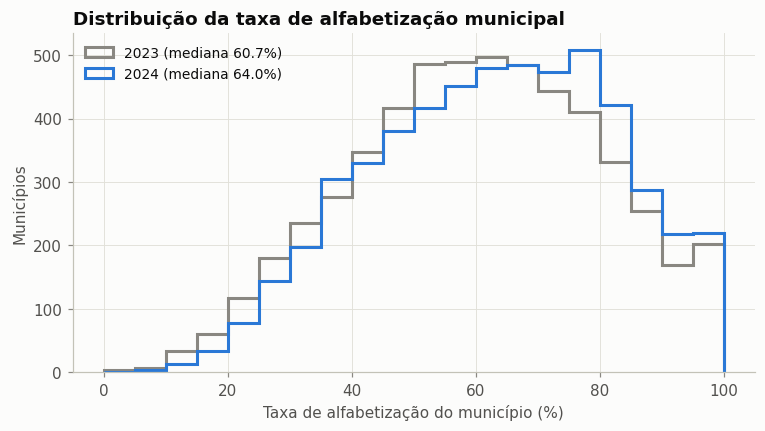

,count,mean,std,min,25%,50%,75%,max
ano,,,,,,,,
2023,5448.0,60.3,19.8,4.4,46.5,60.7,75.0,100.0
2024,5448.0,62.8,19.3,4.4,48.3,64.0,77.6,100.0


In [3]:
# Histograma da taxa municipal (rede Municipal) em 2023 e 2024.
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 101, 5)
for ano, cor in [(2023, CINZA), (2024, AZUL)]:
    v = mun.loc[mun["ano"] == ano, "taxa_alfabetizacao"].dropna()
    ax.hist(v, bins=bins, histtype="step", linewidth=2, color=cor, label=f"{ano} (mediana {v.median():.1f}%)")
ax.set_xlabel("Taxa de alfabetização do município (%)")
ax.set_ylabel("Municípios")
ax.set_title("Distribuição da taxa de alfabetização municipal")
ax.legend()
salvar(fig, "eda_01_distribuicao_taxa_municipal")
plt.show()
mun.groupby("ano")["taxa_alfabetizacao"].describe().round(1)

- **As taxas variaram muito entre municípios:** foram de menos de 10% a 100% de alunos alfabetizados.
- **O cenário melhorou de 2023 para 2024:** a mediana municipal subiu de 60,7% para 64,0%.
- **O contexto do município provavelmente influencia o resultado do aluno.** Com diferenças tão grandes
  entre municípios, é razoável supor que características locais expliquem parte do desempenho individual.
  Por isso, a base de alunos foi enriquecida com variáveis municipais, e o modelo vai testar essa hipótese.

## 3. Padrões territoriais

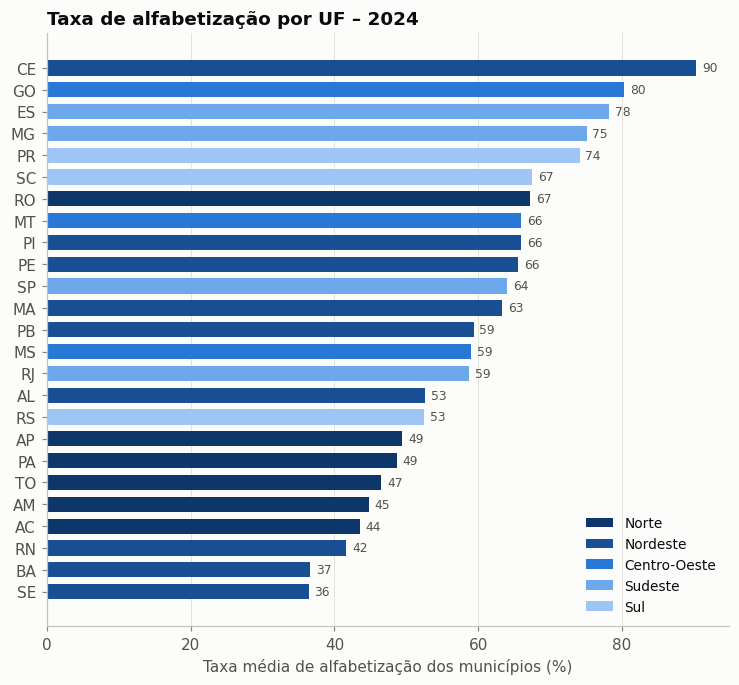

In [4]:
# Taxa média municipal por UF em 2024, colorida pela região.
uf = (mun24.groupby(["sigla_uf", "regiao"])["taxa_alfabetizacao"].mean()
      .reset_index().sort_values("taxa_alfabetizacao"))
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(uf["sigla_uf"], uf["taxa_alfabetizacao"], color=uf["regiao"].map(COR_REGIAO), height=0.7)
for y, v in enumerate(uf["taxa_alfabetizacao"]):
    ax.text(v + 0.8, y, f"{v:.0f}", va="center", fontsize=8, color=TEXTO_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Taxa média de alfabetização dos municípios (%)")
ax.set_title("Taxa de alfabetização por UF – 2024")
handles = [plt.Rectangle((0, 0), 1, 1, color=COR_REGIAO[r]) for r in REGIOES]
ax.legend(handles, REGIOES, loc="lower right")
salvar(fig, "eda_02_taxa_por_uf")
plt.show()

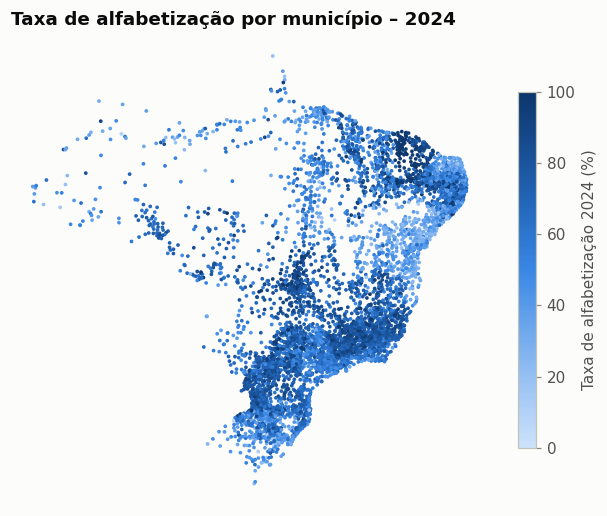

In [5]:
# Mapa aproximado (coordenadas da sede municipal) colorido pela taxa de 2024.
fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(mun24["longitude"], mun24["latitude"], c=mun24["taxa_alfabetizacao"], cmap=SEQ_AZUL,
                s=6, vmin=0, vmax=100, linewidths=0)
ax.set_aspect("equal"); ax.grid(False)
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
plt.colorbar(sc, ax=ax, shrink=0.6, label="Taxa de alfabetização 2024 (%)")
ax.set_title("Taxa de alfabetização por município – 2024")
salvar(fig, "eda_03_mapa_taxa")
plt.show()

In [6]:
# Quanto da variação entre municípios é explicada apenas pela UF? (R² / eta² do efeito UF)
x = mun24.dropna(subset=["taxa_alfabetizacao"])
r2_uf = 1 - x.groupby("sigla_uf")["taxa_alfabetizacao"].transform(lambda s: s - s.mean()).var() / x["taxa_alfabetizacao"].var()
r2_reg = 1 - x.groupby("regiao")["taxa_alfabetizacao"].transform(lambda s: s - s.mean()).var() / x["taxa_alfabetizacao"].var()
print(f"Variância explicada pela UF:    {r2_uf:.1%}")
print(f"Variância explicada pela região: {r2_reg:.1%}")

Variância explicada pela UF:    48.5%
Variância explicada pela região: 13.8%


**Conclusões**
- **A UF é o recorte territorial que mais explica as diferenças.** Sozinha, a UF explica cerca de 48% da
  variação entre municípios em 2024. A região explica só 14%.
- **A diferença entre estados não acompanha a riqueza.** Os municípios do Ceará tiveram taxa média de 90%,
  contra 36% em Sergipe e na Bahia, embora o IDHM médio cearense (0,62) esteja abaixo da média nacional (0,66).
- **Uma explicação possível é a política estadual.** O padrão é compatível com a literatura sobre programas
  de alfabetização em colaboração entre estado e municípios, como o PAIC no Ceará. Esta análise não testa
  essa causa: é uma hipótese apoiada pela literatura.
- **Decisão de modelagem:** o modelo recebe a UF e a região como variáveis categóricas (`sigla_uf` e
  `regiao`, com One-Hot) e a taxa estadual do ano anterior como variável numérica.

## 4. Fatores socioeconômicos

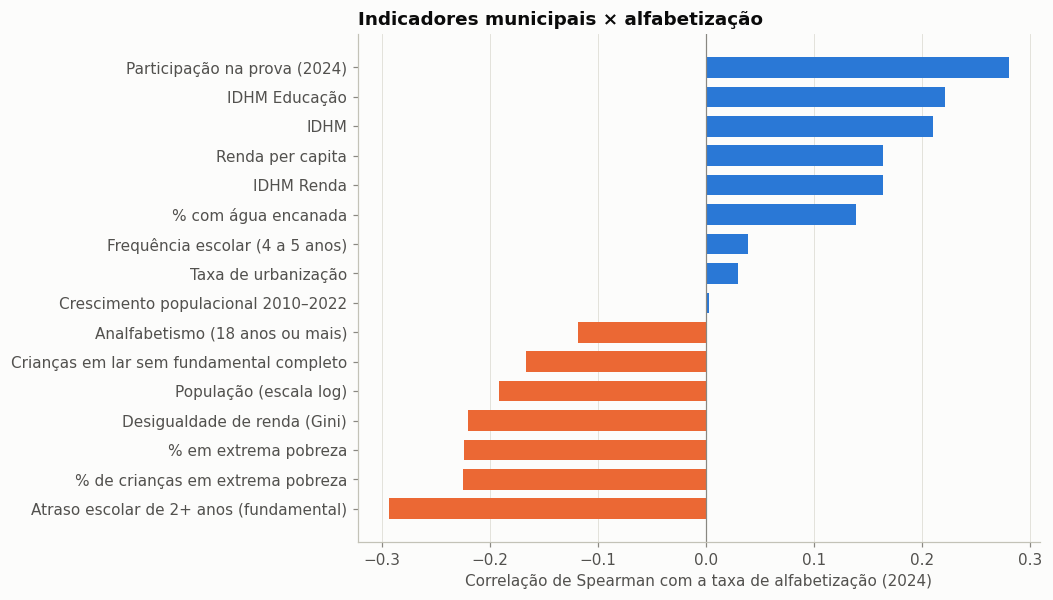

,spearman
taxa_atraso_2anos_fund,-0.293
pct_criancas_extrema_pobreza,-0.225
pct_extrema_pobreza,-0.224
gini,-0.220
log_populacao,-0.192
pct_criancas_lar_sem_fund_completo,-0.166
taxa_analfabetismo_18mais,-0.118
crescimento_pop_2010_2022,0.003
taxa_urbanizacao_2010,0.029
taxa_freq_escola_4a5,0.038


In [7]:
# Correlação de Spearman entre indicadores municipais e a taxa de alfabetização de 2024.
vars_socio = ["idhm", "idhm_educacao", "idhm_renda", "renda_per_capita", "pct_extrema_pobreza",
              "pct_criancas_extrema_pobreza", "gini", "taxa_analfabetismo_18mais", "taxa_atraso_2anos_fund",
              "pct_criancas_lar_sem_fund_completo", "taxa_freq_escola_4a5", "pct_agua_encanada",
              "taxa_urbanizacao_2010", "log_populacao", "crescimento_pop_2010_2022", "percentual_participacao"]
corr = mun24[vars_socio + ["taxa_alfabetizacao"]].corr(method="spearman")["taxa_alfabetizacao"].drop("taxa_alfabetizacao").sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ROTULOS = {
    "idhm": "IDHM", "idhm_educacao": "IDHM Educação", "idhm_renda": "IDHM Renda",
    "renda_per_capita": "Renda per capita", "pct_extrema_pobreza": "% em extrema pobreza",
    "pct_criancas_extrema_pobreza": "% de crianças em extrema pobreza", "gini": "Desigualdade de renda (Gini)",
    "taxa_analfabetismo_18mais": "Analfabetismo (18 anos ou mais)",
    "taxa_atraso_2anos_fund": "Atraso escolar de 2+ anos (fundamental)",
    "pct_criancas_lar_sem_fund_completo": "Crianças em lar sem fundamental completo",
    "taxa_freq_escola_4a5": "Frequência escolar (4 a 5 anos)", "pct_agua_encanada": "% com água encanada",
    "taxa_urbanizacao_2010": "Taxa de urbanização", "log_populacao": "População (escala log)",
    "crescimento_pop_2010_2022": "Crescimento populacional 2010–2022",
    "percentual_participacao": "Participação na prova (2024)",
}
ax.barh(corr.index.map(ROTULOS), corr.values, color=np.where(corr > 0, AZUL, LARANJA), height=0.7)
ax.axvline(0, color=CINZA, linewidth=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlação de Spearman com a taxa de alfabetização (2024)")
ax.set_title("Indicadores municipais × alfabetização")
salvar(fig, "eda_04_correlacoes_socioeconomicas")
plt.show()
corr.round(3).to_frame("spearman")

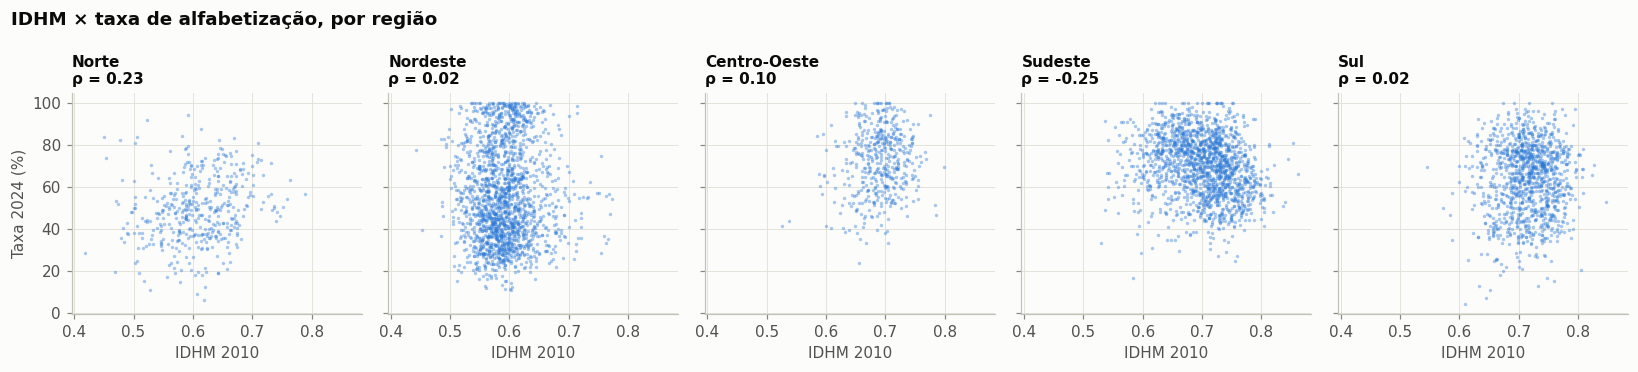

In [8]:
# O efeito socioeconômico é o mesmo em todas as regiões? IDHM × taxa por região.
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharex=True, sharey=True)
for ax, reg in zip(axes, REGIOES):
    d = mun24[mun24["regiao"] == reg].dropna(subset=["idhm", "taxa_alfabetizacao"])
    rho = stats.spearmanr(d["idhm"], d["taxa_alfabetizacao"]).statistic
    ax.scatter(d["idhm"], d["taxa_alfabetizacao"], s=5, alpha=0.4, color=AZUL, linewidths=0)
    ax.set_title(f"{reg}\nρ = {rho:.2f}", fontsize=10)
    ax.set_xlabel("IDHM 2010")
axes[0].set_ylabel("Taxa 2024 (%)")
fig.suptitle("IDHM × taxa de alfabetização, por região", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "eda_05_idhm_por_regiao")
plt.show()

**Conclusões**
- **Os indicadores socioeconômicos estão associados à alfabetização, mas menos que o território.** A
  associação é de fraca a moderada (|ρ| entre 0,2 e 0,3) e vai no sentido esperado: municípios com mais
  pobreza, desigualdade e atraso escolar tiveram, em média, menos alunos alfabetizados em 2024. Isso é
  correlação e não indica, por si só, causa.
- **A participação na prova é o indicador com maior associação** (ρ = 0,28): municípios que levaram mais
  alunos à avaliação tiveram taxas maiores. A direção dessa relação não está clara. A participação pode
  refletir uma rede mais organizada, e não necessariamente causar o resultado.
- **A associação muda de região para região.** Em 2024, IDHM maior acompanhou taxas maiores no Norte
  (ρ = 0,23), não teve relação no Nordeste e no Sul (ρ ≈ 0,02) e teve relação inversa no Sudeste (ρ = −0,25).
  Esse padrão sugere uma interação entre região e socioeconomia, que modelos lineares simples não captam.
- **Municípios maiores tiveram taxas menores** (ρ ≈ −0,19), ao contrário da intuição de que centros urbanos
  teriam melhor desempenho.
- **Decisão de modelagem:** testar modelos de árvore (Random Forest e Gradient Boosting), que captam
  interações e relações não lineares, e compará-los com uma Regressão Logística como referência.

## 5. Persistência do desempenho

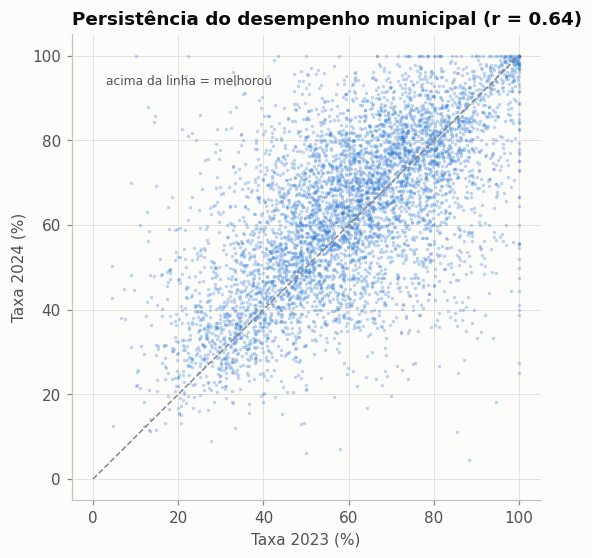

tendencia
MELHORA    3134
PIORA      2250
ESTAVEL      12
Name: count, dtype: int64

In [9]:
# O resultado de 2023 antecipa o de 2024?
ev = carregar_gold("gold_municipio_evolucao").dropna(subset=["taxa_alfabetizacao_2023", "taxa_alfabetizacao_2024"])
r = ev[["taxa_alfabetizacao_2023", "taxa_alfabetizacao_2024"]].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(ev["taxa_alfabetizacao_2023"], ev["taxa_alfabetizacao_2024"], s=5, alpha=0.3, color=AZUL, linewidths=0)
ax.plot([0, 100], [0, 100], color=CINZA, linewidth=1, linestyle="--")
ax.text(3, 93, "acima da linha = melhorou", color=TEXTO_2, fontsize=8)
ax.set_xlabel("Taxa 2023 (%)"); ax.set_ylabel("Taxa 2024 (%)")
ax.set_title(f"Persistência do desempenho municipal (r = {r:.2f})")
salvar(fig, "eda_06_persistencia")
plt.show()
ev["tendencia"].value_counts()

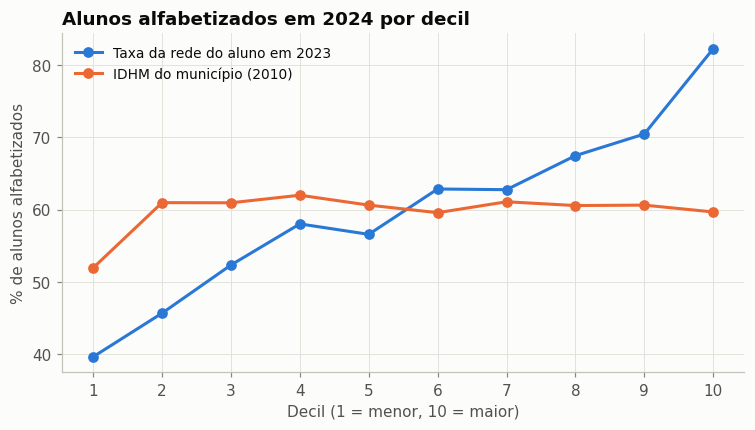

,Taxa da rede do aluno em 2023,IDHM do município (2010)
1,39.6,51.9
2,45.7,61.0
3,52.3,61.0
4,58.0,62.0
5,56.6,60.6
6,62.9,59.6
7,62.8,61.1
8,67.5,60.6
9,70.5,60.6
10,82.3,59.7


In [10]:
# Taxa de alfabetização dos ALUNOS de 2024 por decil da taxa da sua rede no município em 2023 comparada com decis do IDHM do município.
def por_decil(col):
    d = alunos.dropna(subset=[col])
    return d.groupby(pd.qcut(d[col].rank(method="first"), 10, labels=range(1, 11)), observed=True)["alfabetizado"].mean()

dec = pd.DataFrame({"Taxa da rede do aluno em 2023": por_decil("taxa_rede_aluno_ant"),
                    "IDHM do município (2010)": por_decil("idhm")})
fig, ax = plt.subplots(figsize=(8, 4))
for (nome, s), cor in zip(dec.items(), [AZUL, LARANJA]):
    ax.plot(s.index.astype(int), s.values * 100, marker="o", color=cor, label=nome)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decil (1 = menor, 10 = maior)"); ax.set_ylabel("% de alunos alfabetizados")
ax.set_title("Alunos alfabetizados em 2024 por decil")
ax.legend(loc="upper left")
salvar(fig, "eda_07_decis_aluno")
plt.show()
(dec * 100).round(1)

**Conclusões**
- **O resultado de 2023 foi um bom indicador do de 2024, mas não garantiu o resultado.** A correlação entre
  os dois anos foi alta (r ≈ 0,64), e ainda assim 42% dos municípios pioraram.
- **Entre as variáveis analisadas, o resultado anterior da rede é a que mais separa os alunos.** Entre os
  alunos das redes com pior resultado em 2023, 40% estavam alfabetizados em 2024. Entre os das melhores
  redes, 82%. O IDHM, sozinho, quase não separou esses grupos.
- **Decisão de modelagem:** os indicadores educacionais do ano anterior são as variáveis mais
  promissoras. Os do mesmo ano ficam de fora, porque já contêm o resultado do próprio aluno.

## 6. Variáveis do aluno: rede e caderno

In [11]:
# Taxa de alfabetização por rede e teste qui-quadrado de independência.
for col in ["rede_ensino", "caderno"]:
    tab = pd.crosstab(alunos[col], alunos["alfabetizado"])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v_cramer = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    print(f"{col:12s} -> qui² = {chi2:7.1f} | gl = {dof:2d} | p-valor = {p:.4f} | V de Cramér = {v_cramer:.3f}")
alunos.groupby("rede_ensino")["alfabetizado"].agg(["mean", "count"]).round(3)

rede_ensino  -> qui² =    27.4 | gl =  1 | p-valor = 0.0000 | V de Cramér = 0.023
caderno      -> qui² =    31.7 | gl = 20 | p-valor = 0.0461 | V de Cramér = 0.025


,mean,count
rede_ensino,,
Estadual,0.628,6429
Municipal,0.594,43222


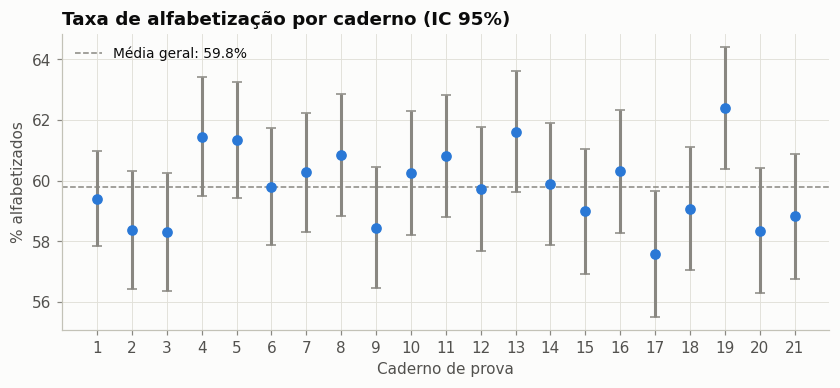

In [12]:
# Taxa por caderno de prova com intervalo de confiança de 95%.
cad = alunos.groupby("caderno")["alfabetizado"].agg(["mean", "count"])
cad["ic"] = 1.96 * np.sqrt(cad["mean"] * (1 - cad["mean"]) / cad["count"])
cad = cad.loc[sorted(cad.index, key=int)]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(cad.index, cad["mean"] * 100, yerr=cad["ic"] * 100, fmt="o", color=AZUL, ecolor=CINZA, capsize=3)
media = alunos["alfabetizado"].mean() * 100
ax.axhline(media, color=CINZA, linestyle="--", linewidth=1, label=f"Média geral: {media:.1f}%")
ax.legend(loc="upper left")
ax.set_xlabel("Caderno de prova"); ax.set_ylabel("% alfabetizados")
ax.set_title("Taxa de alfabetização por caderno (IC 95%)")
salvar(fig, "eda_08_caderno")
plt.show()

**Conclusões**
- **Alunos da rede estadual tiveram taxa um pouco maior:** 62,8%, contra 59,4% na rede municipal em 2024.
  A diferença é pequena (V de Cramér ≈ 0,02), mas estatisticamente consistente (p < 0,001).
- **Não há evidência de que a versão da prova influencie o resultado.** A associação com o caderno é
  marginal (p ≈ 0,046, com 21 cadernos) e de efeito desprezível. Os intervalos de confiança se sobrepõem,
  como se espera de provas equivalentes.
- **Decisão de modelagem:** manter `rede_ensino`, que também define qual resultado anterior o aluno recebe
  (o da rede estadual ou o da municipal). Excluir `caderno`, que acrescentaria 21 categorias sem sinal
  relevante.

## 7. Porte do município

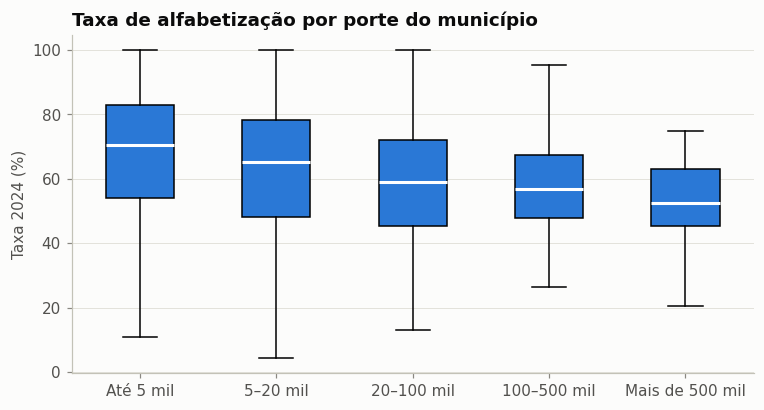

,count,mean,std
porte_municipio,,,
Até 5 mil,1261,67.5,19.9
5–20 mil,2492,63.2,19.6
20–100 mil,1380,59.2,18.3
100–500 mil,275,57.4,13.8
Mais de 500 mil,40,52.7,12.4


In [13]:
# Distribuição da taxa por porte populacional.
ordem = ["Até 5 mil", "5–20 mil", "20–100 mil", "100–500 mil", "Mais de 500 mil"]
dados = [mun24.loc[mun24["porte_municipio"] == p, "taxa_alfabetizacao"].dropna() for p in ordem]
fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot(dados, tick_labels=ordem, patch_artist=True, widths=0.5, showfliers=False,
                medianprops=dict(color="white", linewidth=2))
for b in bp["boxes"]: b.set_facecolor(AZUL)
ax.set_ylabel("Taxa 2024 (%)"); ax.set_title("Taxa de alfabetização por porte do município")
ax.grid(axis="x", visible=False)
salvar(fig, "eda_09_porte")
plt.show()
mun24.groupby("porte_municipio")["taxa_alfabetizacao"].agg(["count", "mean", "std"]).loc[ordem].round(1)

**Conclusões**
- **Municípios pequenos tiveram a maior média e a maior variação.** Os com até 5 mil habitantes
  alfabetizaram 67,5% em média, contra 52,7% nos com mais de 500 mil, mas a variação entre eles também foi
  maior (desvio padrão de 19,9 contra 12,4 pontos).
- **Uma explicação provável é o número de alunos avaliados.** Com poucas crianças, cada aluno pesa mais na
  taxa, que tende a oscilar mais de um ano para o outro. Esta análise não mediu esse efeito diretamente.
- **Implicação:** as previsões para municípios pequenos tendem a ter mais incerteza. Isso precisa ser
  considerado ao interpretar o risco de não atingir a meta e entra nas limitações do projeto.

## 8. Quem não atingiu a meta de 2024?

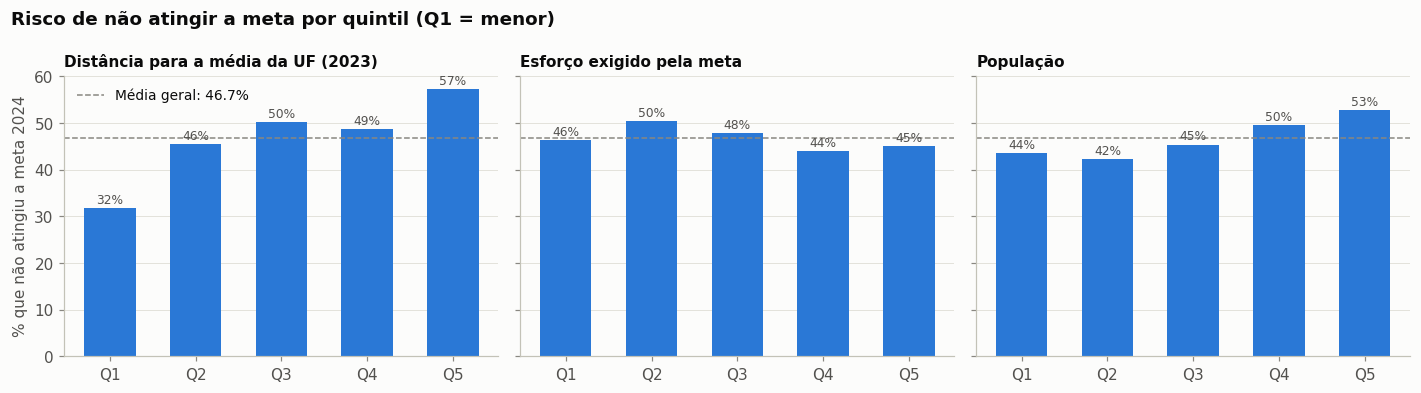

,Distância para a média da UF (2023),Esforço exigido pela meta,População
Q1,31.7,46.3,43.6
Q2,45.6,50.4,42.3
Q3,50.2,47.8,45.4
Q4,48.8,44.0,49.5
Q5,57.3,45.0,52.8


In [14]:
# % de municípios que NÃO atingiram a meta de 2024 por quintil de variáveis de 2023.
def risco_por_quintil(col, rotulo):
    q = pd.qcut(base_meta[col], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
    return base_meta.groupby(q, observed=True)["nao_atingiu_meta"].mean().rename(rotulo)

r = pd.concat([risco_por_quintil("gap_para_uf", "Distância para a média da UF (2023)"),
               risco_por_quintil("esforco_meta", "Esforço exigido pela meta"),
               risco_por_quintil("populacao_2022", "População")], axis=1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, col in zip(axes, r.columns):
    ax.bar(r.index, r[col] * 100, color=AZUL, width=0.6)
    media = base_meta["nao_atingiu_meta"].mean() * 100
    ax.axhline(media, color=CINZA, linestyle="--", linewidth=1, label=f"Média geral: {media:.1f}%")
    for i, v in enumerate(r[col] * 100):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=TEXTO_2)
    ax.set_title(col, fontsize=10); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% que não atingiu a meta 2024")
axes[0].legend(loc="upper left")
fig.suptitle("Risco de não atingir a meta por quintil (Q1 = menor)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "eda_10_risco_meta_quintis")
plt.show()
(r * 100).round(1)

**Conclusões**
- **Municípios muito acima do próprio estado em 2023 deixaram de atingir a meta de 2024 com mais
  frequência.** Entre os que mais superavam a média estadual, 57% não atingiram a meta, contra 32% entre os
  que estavam mais abaixo. O padrão é compatível com a regressão à média: resultados excepcionais tendem a
  não se repetir, principalmente em municípios pequenos. É uma interpretação, não uma causa comprovada.
- **O tamanho do salto exigido pela meta não diferenciou quem deixou de atingi-la.** O percentual ficou
  entre 44% e 50% em todas as faixas de esforço (meta de 2024 menos taxa de 2023).
- **Municípios maiores deixaram de atingir a meta com mais frequência:** 53% entre os maiores, contra 44%
  entre os menores.
- **Decisão de modelagem:** o modelo municipal inclui a posição em relação ao estado (`gap_para_uf`), o
  esforço exigido, o porte e a participação na avaliação.

## 9. Síntese: hipóteses que orientam a modelagem

As hipóteses abaixo vêm de **associações observadas em 2023 e 2024**. Elas orientam a construção do
modelo, mas não comprovam causa. Os notebooks 04 e 05 testam se elas se sustentam.

| # | Hipótese | Evidência observada | Como entra no modelo |
|---|---|---|---|
| H1 | O **estado** pesa mais que a renda | A UF explicou ~48% da variação em 2024; o Ceará liderou com IDHM abaixo da média | UF e região (One-Hot) e taxa estadual do ano anterior |
| H2 | O **resultado passado** ajuda a antecipar o futuro | r = 0,64 entre 2023 e 2024; alunos foram de 40% a 82% de alfabetizados conforme a rede | Taxas e médias de 2023 por rede |
| H3 | A socioeconomia importa, mas **de forma diferente em cada região** | Associação fraca a moderada, com sinal que muda entre regiões | Modelos de árvore, comparados com a Regressão Logística |
| H4 | A **versão da prova** não influencia o resultado | Efeito desprezível (V ≈ 0,025) | Variável excluída |
| H5 | Resultados excepcionais **tendem a recuar** | 57% de não atingimento entre os que mais superavam o estado, contra 32% | `gap_para_uf` no modelo de metas |
| H6 | Municípios **pequenos são mais instáveis** | Maior desvio padrão nas taxas | Tratado nas limitações e na incerteza das previsões |

**Como o modelo será validado:** alunos do mesmo município compartilham as mesmas variáveis de contexto.
Por isso, a separação entre treino e teste é feita **por município** (GroupKFold). Assim, o modelo é
avaliado em municípios que nunca viu, que é o cenário real de uso.